In [1]:
import os, glob, numpy as np, pandas as pd
paths = glob.glob("/kaggle/input/**/*_raw_vs_den.csv", recursive=True)
print(paths)
meld = pd.read_csv([p for p in paths if "meld" in p][0])
iem  = pd.read_csv([p for p in paths if "iemocap" in p][0])
print(meld.shape, iem.shape)
print(meld[["denoise_sec"]].describe().T)

['/kaggle/input/datasets/kushalag21/speechcuellm-denoise-diag/iemocap_raw_vs_den.csv', '/kaggle/input/datasets/kushalag21/speechcuellm-denoise-diag/meld_raw_vs_den.csv']
(1000, 19) (1000, 19)
              count      mean      std       min       25%       50%  \
denoise_sec  1000.0  0.057625  0.03213  0.010539  0.036258  0.049157   

                  75%       max  
denoise_sec  0.070139  0.243487  


In [2]:
from scipy.stats import spearmanr, ks_2samp
F = {"volume avg": "avg_intensity", "volume var": "intensity_variation",
     "pitch avg": "avg_pitch", "pitch var": "pitch_std", "speaking rate": "articulation_rate"}
def shift(df):
    rows = []
    for name, c in F.items():
        r = pd.to_numeric(df[f"raw_{c}"], errors="coerce"); d = pd.to_numeric(df[f"den_{c}"], errors="coerce")
        m = r.notna() & d.notna()
        rows.append({"feature": name, "raw_median": r[m].median(), "den_median": d[m].median(),
                     "median_shift_%": 100*(d[m].median()-r[m].median())/abs(r[m].median()),
                     "spearman": spearmanr(r[m], d[m])[0], "KS": ks_2samp(r[m], d[m])[0]})
    return pd.DataFrame(rows).round(3)
print("MELD\n", shift(meld)); print("IEMOCAP\n", shift(iem))

MELD
          feature  raw_median  den_median  median_shift_%  spearman     KS
0     volume avg      62.933      73.648          17.026     0.346  0.842
1     volume var       8.261      11.659          41.130     0.414  0.446
2      pitch avg     226.659     231.034           1.930     0.810  0.032
3      pitch var      62.579      64.821           3.582     0.460  0.065
4  speaking rate       3.961       4.226           6.689     0.424  0.146
IEMOCAP
          feature  raw_median  den_median  median_shift_%  spearman     KS
0     volume avg      59.182      73.278          23.818     0.124  0.822
1     volume var       9.241      11.174          20.922     0.626  0.348
2      pitch avg     196.100     218.747          11.549     0.749  0.163
3      pitch var      58.111      70.631          21.546     0.294  0.191
4  speaking rate       4.055       4.382           8.063     0.455  0.146


In [3]:
Q = [0.1, 0.25, 0.75, 0.9]
def agreement(df):
    out = {}
    for name, c in F.items():
        r = pd.to_numeric(df[f"raw_{c}"], errors="coerce"); d = pd.to_numeric(df[f"den_{c}"], errors="coerce")
        m = r.notna() & d.notna(); r, d = r[m], d[m]
        raw_cls    = np.digitize(r, np.quantile(r, Q))      # raw values, raw thresholds (the paper's setup)
        frozen_cls = np.digitize(d, np.quantile(r, Q))      # denoised values, raw thresholds
        recomp_cls = np.digitize(d, np.quantile(d, Q))      # denoised values, recomputed thresholds
        out[name] = {"same bucket, frozen %": 100*(raw_cls == frozen_cls).mean(),
                     "same bucket, recomputed %": 100*(raw_cls == recomp_cls).mean()}
    return pd.DataFrame(out).T.round(1)
print("MELD\n", agreement(meld)); print("IEMOCAP\n", agreement(iem))

MELD
                same bucket, frozen %  same bucket, recomputed %
volume avg                      11.0                       37.4
volume var                      23.8                       44.3
pitch avg                       67.2                       67.5
pitch var                       49.2                       52.1
speaking rate                   35.4                       42.3
IEMOCAP
                same bucket, frozen %  same bucket, recomputed %
volume avg                      10.6                       35.9
volume var                      28.0                       48.2
pitch avg                       56.7                       55.6
pitch var                       40.9                       44.5
speaking rate                   40.7                       43.4


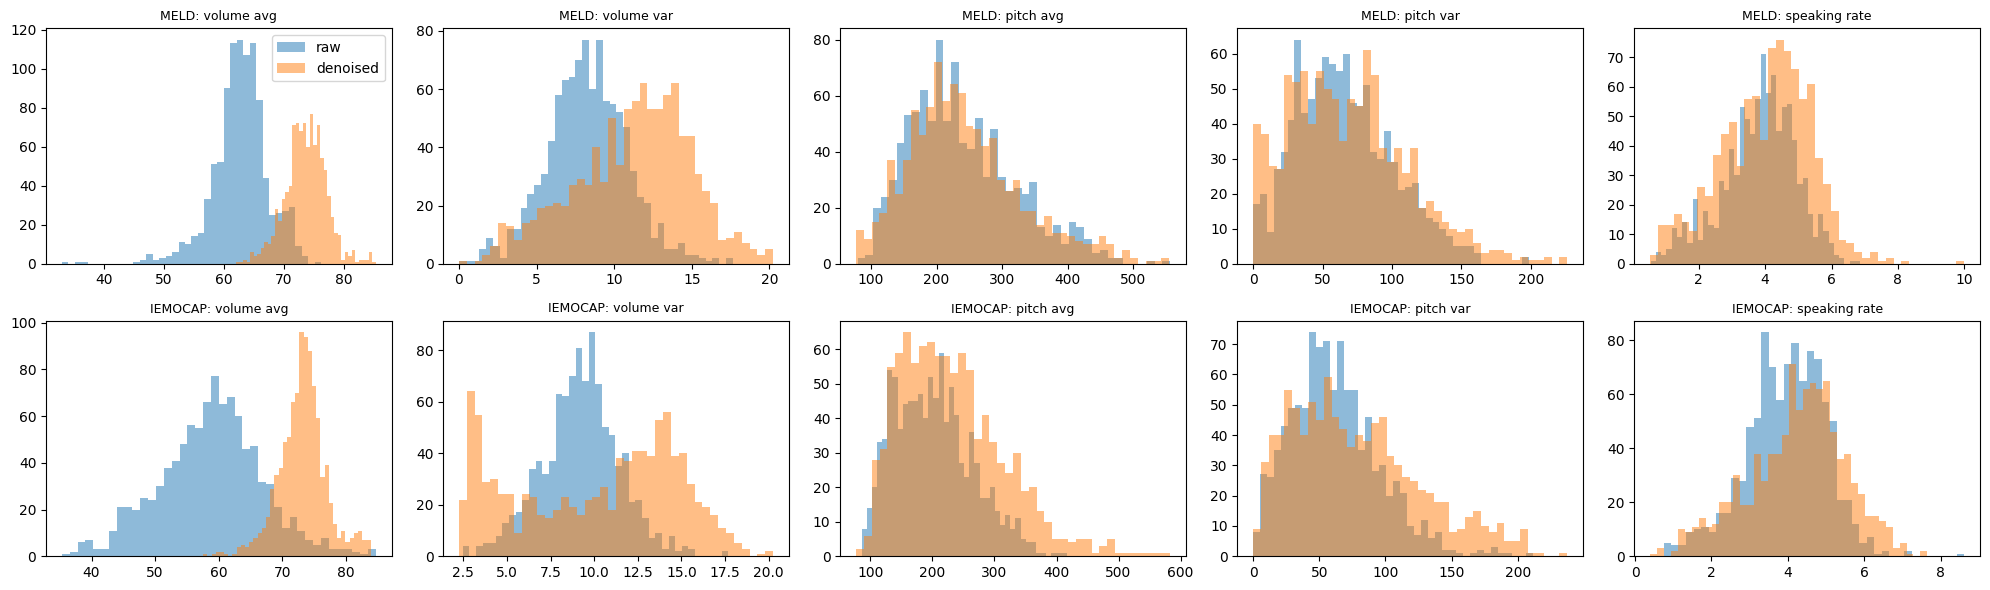

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 5, figsize=(20, 6))
for i, (df, nm) in enumerate([(meld, "MELD"), (iem, "IEMOCAP")]):
    for j, (name, c) in enumerate(F.items()):
        r = pd.to_numeric(df[f"raw_{c}"], errors="coerce").dropna(); d = pd.to_numeric(df[f"den_{c}"], errors="coerce").dropna()
        ax[i, j].hist(r, bins=40, alpha=.5, label="raw"); ax[i, j].hist(d, bins=40, alpha=.5, label="denoised")
        ax[i, j].set_title(f"{nm}: {name}", fontsize=9)
ax[0, 0].legend(); plt.tight_layout(); plt.savefig("/kaggle/working/distributions.png", dpi=150); plt.show()

In [5]:
for nm, df in [("MELD", meld), ("IEMOCAP", iem)]:
    gain = df["rms_den"] - df["rms_raw"]
    corrected = pd.to_numeric(df["den_avg_intensity"], errors="coerce") - gain
    r = pd.to_numeric(df["raw_avg_intensity"], errors="coerce")
    m = corrected.notna() & r.notna()
    print(nm, "Spearman raw vs gain-corrected denoised volume:", round(spearmanr(r[m], corrected[m])[0], 3))

MELD Spearman raw vs gain-corrected denoised volume: 0.995
IEMOCAP Spearman raw vs gain-corrected denoised volume: 1.0


In [6]:
!git clone -q https://github.com/zehuiwu/SpeechCueLLM.git
!grep -n "pitch_std\|pitch_range\|intensity_variation\|articulation" SpeechCueLLM/LLM_code/data_process.py SpeechCueLLM/LLM_code/data_utils/*.py | head -20

SpeechCueLLM/LLM_code/data_process.py:97:                        intensity_variation = filtered_rows['intensity_variation_category'].values[0]
SpeechCueLLM/LLM_code/data_process.py:99:                        pitch_variation = filtered_rows['pitch_std_category'].values[0]
SpeechCueLLM/LLM_code/data_process.py:101:                        # temp_content_str += f' ({avg_intensity} volume with {intensity_variation} variation)'
SpeechCueLLM/LLM_code/data_process.py:122:                        intensity_variation = filtered_rows['intensity_variation_category'].values[0]
SpeechCueLLM/LLM_code/data_process.py:124:                        pitch_variation = filtered_rows['pitch_std_category'].values[0]
SpeechCueLLM/LLM_code/data_process.py:126:                        #temp_content_str += f' ({avg_intensity} volume with {intensity_variation} variation)'


In [7]:
Q = [0.1, 0.25, 0.75, 0.9]
for nm, df in [("MELD", meld), ("IEMOCAP", iem)]:
    r = pd.to_numeric(df["raw_avg_intensity"], errors="coerce")
    d = pd.to_numeric(df["den_avg_intensity"], errors="coerce") - (df["rms_den"] - df["rms_raw"])
    m = r.notna() & d.notna(); r, d = r[m], d[m]
    same = (np.digitize(r, np.quantile(r, Q)) == np.digitize(d, np.quantile(r, Q))).mean()
    print(nm, "volume avg, frozen thresholds, level-matched: same bucket", round(100*same, 1), "%")

MELD volume avg, frozen thresholds, level-matched: same bucket 97.2 %
IEMOCAP volume avg, frozen thresholds, level-matched: same bucket 99.2 %


In [8]:
shift(meld).to_csv("/kaggle/working/shift_meld.csv", index=False)
shift(iem).to_csv("/kaggle/working/shift_iemocap.csv", index=False)
agreement(meld).to_csv("/kaggle/working/threshold_agreement_meld.csv")
agreement(iem).to_csv("/kaggle/working/threshold_agreement_iemocap.csv")
print(os.listdir("/kaggle/working"))

['threshold_agreement_meld.csv', '__notebook__.ipynb', 'SpeechCueLLM', 'shift_iemocap.csv', 'threshold_agreement_iemocap.csv', 'distributions.png', 'shift_meld.csv']
